# Menu-cost model with Krusell–Smith aggregation

Heterogeneous firms face menu costs and aggregate monetary shocks, with a two-coefficient forecasting rule for the normalized price index.

This simple notebook solves the model with JAX, using JIT compilation, vectorization, and broadcasting for an efficient CPU run. 

It follows a simplified version of the solution method in Vavra’s [*Inflation Dynamics and Time-Varying Volatility*](https://www.nber.org/papers/w19148).

## 1. Environment

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu" # Pretty important for GPU or CPU depending on your JAX install.
import time

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import menucost as mc

from statsmodels.tsa.filters.hp_filter import hpfilter
from scipy.stats import kurtosis


## 2. Calibration

In [2]:
SEED = 999

θ = 6.8
mp = mc.ModelParameters(
    rhoz=0.62, sigz=0.0426, pz=0.13,    # Idiosyncratic Productivity
    ω=(θ - 1) / θ,                      # labor Disutility
    f=0.09,                             # Menu Cost
    α=0.09,                             # Calvo Plus (prob of zero cost)
    θ=θ,                                # CES elasticity
    β=0.997,
    μ=0.002,                            # Money Growth mean
    sigs=0.0037,                        # Money Growth standard deviation
    tauchen_spread=3.0,
    zn=7, pn=51, chin=11, mn=5,         # Grid sizes 
)
vp = mc.VFIParameters(vfi_tol=1e-4, vfi_maxiter=6000)
kp = mc.KSParameters(nfirm=400, ntime=600, nburn=80, damp=0.5, ks_tol=0.005, ks_maxiter=12)
coef0 = mc.CoefParameters(gam0=0.0, gam1=0.62)

## 3. Grids and Draws

In [3]:
sg = mc.create_shock_grids(mp)
draws = mc.draw_shocks(kp, mp, sg, jax.random.PRNGKey(SEED))
print(f"state space : {mp.chin} aggregate x {mp.pn} price x {mp.zn} productivity")

state space : 11 aggregate x 51 price x 7 productivity


## 4. One Krusell–Smith pass

The first pass is unrolled so each stage is visible.

### 4a. Value function iteration

Given $(\gamma_0, \gamma_1)$ the firm's problem is a standard contraction. The first call
includes JIT compilation, so it is slower than later ones.

In [4]:
coef = coef0
t0 = time.perf_counter()
initial_states = jnp.zeros((mp.chin, mp.pn, mp.zn, 3))
vfi = mc.solve_vfi(initial_states, mp, vp, sg, coef)
print(f"VFI wall time (with compile time): {time.perf_counter() - t0:.1f} s")

VFI iteration 100: error = 1.079e-02
VFI iteration 200: error = 4.207e-03
VFI iteration 300: error = 2.320e-03
VFI iteration 400: error = 1.454e-03
VFI iteration 500: error = 9.727e-04
VFI iteration 600: error = 6.757e-04
VFI iteration 700: error = 4.809e-04
VFI iteration 800: error = 3.478e-04
VFI iteration 900: error = 2.543e-04
VFI iteration 1000: error = 1.875e-04
VFI iteration 1100: error = 1.390e-04
VFI iteration 1200: error = 1.035e-04
VFI iteration 1212: error = 9.992e-05
VFI wall time (with compile time): 0.8 s


### 4b. Policy functions

From the value function we get each firm's decision to reset to the price that maximizes the value
of not adjusting or keep the previous price. 

The plot shows where firms adjust for a given
aggregate state, as a function of the inherited price and productivity. 

Firms inside the light region keep their price; the dark region is where paying the menu cost is worth it.

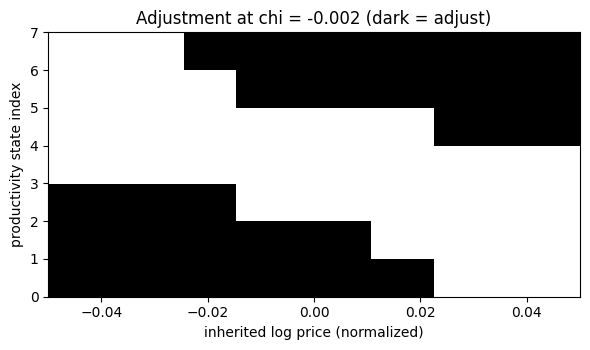

In [5]:
rule = mc.policy_function(vfi.v, sg)

ci = int(np.argmin(np.abs(np.asarray(sg.chigrid)))) 
adjusts = np.asarray(rule.optimal_price[ci]) != np.arange(mp.pn)[:, None]   # (price, z)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow(
    adjusts.T, 
    origin="lower", 
    aspect="auto", 
    cmap="Greys",
    extent=[float(sg.pgrid[0]), float(sg.pgrid[-1]), 0, mp.zn])
ax.set(
    xlabel="inherited log price (normalized)", 
    ylabel="productivity state index",
    title=f"Adjustment at chi = {float(sg.chigrid[ci]):.3f} (dark = adjust)")
fig.tight_layout()
plt.show()

### 4c. Simulate the firm panel
Panel is simulated forward using the decision rules and the fixed draws. 

In [6]:
sim = mc.simulate_panel(mp, sg, draws, rule)
adj_freq = float(np.asarray(sim.adj_freq)[kp.nburn:].mean())
first_pass_seconds = time.perf_counter() - t0

### 4d. Regress and update

Regress the simulated $\log(P/S)$ on $\chi$ over the post-burn-in sample. The KS error compares
the estimate with the rule the firms just used (absolute difference for $\gamma_0$, relative for
$\gamma_1$). The new rule is a damped average of the old rule and the estimate.

In [7]:
chi_s = np.asarray(sim.chi)[kp.nburn:]
logP_s = np.asarray(sim.log_P)[kp.nburn:]

fit = mc.law_of_motion(chi_s, logP_s)

err = float(max(
    abs(fit.coef[0] - coef.gam0),
    abs((fit.coef[1] - coef.gam1) / coef.gam1),
))

new = kp.damp * fit.coef + (1 - kp.damp) * coef.as_array()
coef_next = mc.CoefParameters(gam0=float(new[0]), gam1=float(new[1]))

print(f"γ0 = {fit.coef[0]:.5f}, γ1 = {fit.coef[1]:.5f}, R² = {fit.r2:.4f}")
print(f"Rule used: ({coef.gam0:.5f}, {coef.gam1:.5f})")
print(f"Updated rule: ({coef_next.gam0:.5f}, {coef_next.gam1:.5f})")
print(f"KS error: {err:.3e}, tolerance {kp.ks_tol:.0e}")

γ0 = -0.00110, γ1 = 0.71460, R² = 0.9005
Rule used: (0.00000, 0.62000)
Updated rule: (-0.00055, 0.66730)
KS error: 1.526e-01, tolerance 5e-03


## 5. Iterate to convergence

Repeat the solve–simulate–regress steps, using the previous value function to start each pass.

In [8]:
passes = [mc.KSPass(index=1, coef_used=coef, coef_next=coef_next, error=err, vfi=vfi, rule=rule, sim=sim, fit=fit, seconds=first_pass_seconds)]
print(f"KS pass 1 | gam0 = {fit.coef[0]:.5f}, gam1 = {fit.coef[1]:.5f} | R2 = {fit.r2:.4f} | KS error = {err:.2e}")

converged = err <= kp.ks_tol
for it in range(2, kp.ks_maxiter + 1):
    if converged:
        break
    prev = passes[-1]
    step = mc.ks_pass(it, prev.vfi.v, prev.coef_next, mp, vp, kp, sg, draws)
    passes.append(step)
    converged = step.error <= kp.ks_tol

final = passes[-1]
print(f"Converged: {converged} | Passes: {len(passes)} | KS error: {final.error:.2e}")


KS pass 1 | gam0 = -0.00110, gam1 = 0.71460 | R2 = 0.9005 | KS error = 1.53e-01
VFI iteration 100: error = 3.598e-04
VFI iteration 200: error = 2.651e-04
VFI iteration 300: error = 1.935e-04
VFI iteration 400: error = 1.404e-04
VFI iteration 500: error = 1.014e-04
VFI iteration 505: error = 9.979e-05
Rule used: (-0.00055, 0.66730) | OLS: (-0.00108, 0.71513) | R2 0.9009 | KS error 7.17e-02 | 0.2s
VFI iteration 100: error = 1.155e-04
VFI iteration 144: error = 9.997e-05
Rule used: (-0.00082, 0.69122) | OLS: (-0.00108, 0.71513) | R2 0.9009 | KS error 3.46e-02 | 0.1s
VFI iteration 100: error = 1.970e-04
VFI iteration 200: error = 1.402e-04
VFI iteration 298: error = 9.998e-05
Rule used: (-0.00095, 0.70318) | OLS: (-0.00108, 0.71513) | R2 0.9009 | KS error 1.70e-02 | 0.2s
VFI iteration 100: error = 6.795e-04
VFI iteration 200: error = 4.987e-04
VFI iteration 300: error = 3.717e-04
VFI iteration 400: error = 2.800e-04
VFI iteration 500: error = 2.126e-04
VFI iteration 600: error = 1.624e-04


## 6. Final regression
R2 should be very high 0.97. 

Due to the smaller scale of our experiment this naturally falls. To improve increase grid sizes, number of firms, or simulation time. 

gam0 = -0.00104, gam1 = 0.72083, R2 = 0.9060

rule used in final solve : gam0 = -0.00104, gam1 = 0.71866
final KS error           : 3.02e-03


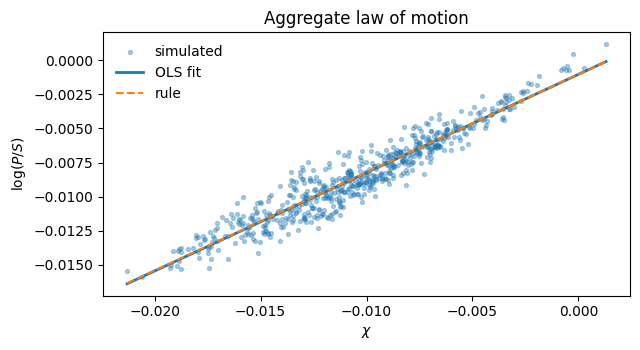

In [9]:
print(f"gam0 = {final.fit.coef[0]:.5f}, gam1 = {final.fit.coef[1]:.5f}, R2 = {final.fit.r2:.4f}")
print(f"\nrule used in final solve : gam0 = {final.coef_used.gam0:+.5f}, gam1 = {final.coef_used.gam1:.5f}")
print(f"final KS error           : {final.error:.2e}")

chi_f = np.asarray(final.sim.chi)[kp.nburn:]
logP_f = np.asarray(final.sim.log_P)[kp.nburn:]
grid = np.linspace(chi_f.min(), chi_f.max(), 50)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(chi_f, logP_f, s=8, alpha=0.35, label="simulated")
ax.plot(grid, final.fit.coef[0] + final.fit.coef[1] * grid, lw=2, label="OLS fit")
ax.plot(grid, final.coef_used.gam0 + final.coef_used.gam1 * grid, lw=1.5, ls="--", label="rule")
ax.set(xlabel=r"$\chi$", ylabel=r"$\log(P/S)$", title="Aggregate law of motion")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 7. Price-change moments

Compute moments from the post-burn-in panel and print them beside manually entered reference values.

In [10]:
psim = np.asarray(final.sim.price_idx)[kp.nburn:].T
pstart_store = np.asarray(final.sim.start_idx)[kp.nburn:].T
Psim = np.asarray(final.sim.log_P)[kp.nburn:]
pgrid = np.asarray(sg.pgrid)

nfirm, ntime = psim.shape

great_psim = np.sum(psim > pstart_store, axis=0)
less_psim = np.sum(psim < pstart_store, axis=0)
neq_psim = np.sum(psim != pstart_store, axis=0)

adjust = neq_psim / nfirm
adjustup = great_psim / neq_psim

aux = np.abs(pgrid[psim] - pgrid[pstart_store])

size = np.sum(aux, axis=0) / neq_psim
sizeup = np.sum((psim > pstart_store) * aux, axis=0) / great_psim
sizedown = np.sum((psim < pstart_store) * aux, axis=0) / less_psim
fracsmall = (
    np.sum(aux < (0.5 * size * (psim != pstart_store)), axis=0)
    / neq_psim
)
kurt = kurtosis(aux[aux != 0], fisher=False, bias=True)

print(f"adjust:     0.11,  {np.median(adjust):.3f}")
print(f"adjustup:   0.66,  {np.median(adjustup):.3f}")
print(f"size:       ----, {np.median(size[~np.isnan(size)]):.3f}")
print(f"sizeup:     0.055, {np.median(sizeup[~np.isnan(sizeup)]):.3f}")
print(f"sizedown:   0.064, {np.median(sizedown[~np.isnan(sizedown)]):.3f}")
print(f"frac small: 0.34,  {np.median(fracsmall[~np.isnan(fracsmall)]):.3f}")
print(f"kurtosis:   7.20,  {kurt:.3f}")

disper = np.zeros(ntime)
for tt in range(ntime):
    col_aux = aux[:, tt]
    disper[tt] = np.std(col_aux[col_aux != 0], ddof=1)

Ysim = 1 / np.exp(Psim)

ts_Ysim = hpfilter(Ysim, lamb=14400)[0]
ts_disper = hpfilter(disper, lamb=14400)[0]
ts_adjust = hpfilter(adjust, lamb=14400)[0]
ts_disper_adjust = hpfilter(disper / adjust, lamb=14400)[0]

print(f"dispfreq:   0.62,  {np.corrcoef(ts_disper, ts_adjust)[0, 1]:.3f}")
print(f"dispY:     -0.60,  {np.corrcoef(ts_disper, ts_Ysim)[0, 1]:.3f}")
print(f"adjustY:   -0.24,  {np.corrcoef(ts_adjust, ts_Ysim)[0, 1]:.3f}")
print(f"dispfreqY: -0.39,  {np.corrcoef(ts_disper_adjust, ts_Ysim)[0, 1]:.3f}")
print(f"stddisper:  0.072, {np.std(ts_disper):.3f}")
print(f"stdadjust:  0.046, {np.std(ts_adjust):.3f}")

adjust:     0.11,  0.083
adjustup:   0.66,  0.786
size:       ----, 0.032
sizeup:     0.055, 0.032
sizedown:   0.064, 0.035
frac small: 0.34,  0.419
kurtosis:   7.20,  2.790
dispfreq:   0.62,  0.052
dispY:     -0.60,  -0.157
adjustY:   -0.24,  -0.099
dispfreqY: -0.39,  -0.005
stddisper:  0.072, 0.004
stdadjust:  0.046, 0.015


/tmp/ipykernel_142186/1372475604.py:19: RuntimeWarning: invalid value encountered in divide
  sizedown = np.sum((psim < pstart_store) * aux, axis=0) / less_psim
